In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d

import seaborn as sns
import librosa
import torch
import torchaudio
import random
from IPython.display import Audio, display

In [2]:
def print_metrics(scores, labels):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)

    #print(f"AUC: {rocauc * 100:.2f}%, EER: {eer * 100:.2f}%")
    return eer, rocauc

def plot_distributions(scores, labels, ax=None, attack='Pseudo-Fakes', metrics=True, F_THR=None, R_THR=None):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]
        
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    sns.kdeplot(real_scores, fill=True, alpha=0.5, label="Real (0)", ax=ax)
    sns.kdeplot(fake_scores, fill=True, alpha=0.5, label="Fake (1)", ax=ax)
    ax.axvline(0, linestyle="--", linewidth=2, color="red")
    if F_THR is not None:
        ax.axvline(R_THR, linestyle="--", linewidth=2, color="black")
        ax.axvline(F_THR, linestyle="--", linewidth=2, color="black")

    ax.set_xlabel("Score")
    ax.set_ylabel("Density")
    ax.legend()
    ax.set_title(f"Target: {attack}")

    if metrics:
        eer, auc = print_metrics(scores, labels)  # <-- usa la tua funzione
        text = (
            f"N={len(scores)}\n"
            f"Real μ={real_scores.mean():.3f}\n"
            f"Fake μ={fake_scores.mean():.3f}\n"
            f"EER={eer:.3f}\n"
            f"AUC={auc:.3f}")
        ax.text(
            0.98, 0.98, text,
            transform=ax.transAxes,
            fontsize=9,
            verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle="round", alpha=0.3))

def plot_raw_scatter(scores, labels, ax=None, metrics=True):
    real_scores = scores[labels == 0]
    fake_scores = scores[labels == 1]

    if metrics:
        print_metrics(scores, labels)

    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 5))

    real_y = np.zeros_like(real_scores)
    fake_y = np.ones_like(fake_scores)

    ax.scatter(real_scores, real_y, alpha=0.5, label="Real (0)")
    ax.scatter(fake_scores, fake_y, alpha=0.5, label="Fake (1)")
    ax.set_xlabel("Score")
    ax.set_ylabel("Label")
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Real", "Fake"])
    ax.legend()

def show_results(mod):
    rootpath = f'/home/smg/v-viola/moe_antideepfake/results/experts/asv19/{mod}'
    res_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'scores.npy'))
    lab_sanity_check = np.load(os.path.join(rootpath, 'SanityCheck', 'labels.npy'))
    
    plot_distributions(res_sanity_check, lab_sanity_check, metrics=True)

    all_logits = []
    all_labels = []
    fig, axes = plt.subplots(1, n_attacks, figsize=(5*n_attacks, 4))
    for i, a in enumerate(attack_list):
        res_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'scores.npy'))
        lab_target_check = np.load(os.path.join(rootpath, 'TargetCheck', a, 'labels.npy'))
        all_logits.append(res_target_check)
        all_labels.append(lab_target_check)
        
        ax = axes[i] if n_attacks > 1 else axes
        plot_distributions(res_target_check, lab_target_check, ax=ax, attack=a, metrics=True)

    return all_logits, all_labels
    

In [3]:
class STFTWindowParams:
    def __init__(self, sample_rate=16000, win_sec=0.032, hop_sec=0.016):
        self.sample_rate = sample_rate
        self.win_sec = win_sec
        self.hop_sec = hop_sec

        self.update()
    def update(self):
        self.win_size = int(self.win_sec * self.sample_rate)
        self.hop_size = int(self.hop_sec * self.sample_rate)
        self.fft_size = self.next_pow_2(self.win_size)
    @staticmethod
    def next_pow_2(x):
        return 2 ** (x - 1).bit_length()

def apply_db(spec):
    spec_db = torchaudio.functional.amplitude_to_DB(
        spec,
        multiplier=10.0, # 4 power spec, change to 20.0 otherwise
        amin=1e-10,
        db_multiplier=0
    )
    return spec_db
    
def spec_extraction(y, stft_params):
    spec_transform = torchaudio.transforms.Spectrogram(
        n_fft=stft_params.fft_size,
        hop_length=stft_params.hop_size,
        power=2
    )
    spec = spec_transform(torch.Tensor(y).unsqueeze(0))
    spec = spec.squeeze(0)
    feat = apply_db(spec)

    return feat

In [4]:
def load_audio_track(path, trim=False, normalize=False, sr=16000, top_db=40):
    waveform, sample_rate = librosa.load(path, sr=None, mono=True)
    waveform = torch.Tensor(waveform).unsqueeze(0)  # gotta fix torchaudio.load

    if sr != sample_rate:
        resampler = torchaudio.transforms.Resample(orig_freq=sample_rate, new_freq=sr)
        waveform = resampler(waveform)
    if normalize:
        peak = waveform.abs().max()
        if peak > 0:
            waveform = waveform / peak
    if trim:
        amplitude_threshold = 10 ** (-top_db / 20)
        non_silent = (waveform.abs() > amplitude_threshold).nonzero(as_tuple=True)[1]
        if non_silent.numel() > 0:
            start = non_silent[0].item()
            end = non_silent[-1].item() + 1
            waveform = waveform[:, start:end]
        else:
            waveform = waveform[:, :0]

    return waveform.squeeze()

def prepare_audio_window(x, max_len=48000, is_eval=True):
    x_len = x.shape[0]

    while x_len < max_len:
        num_samples = min(x_len, max_len - x_len)
        x = torch.cat([x, x[:num_samples]], dim=0)
        x_len = x.shape[0]

    if not is_eval:
        last_valid_start_sample = x_len - max_len
        if not last_valid_start_sample == 0:
            start_sample = random.randrange(start=0, stop=last_valid_start_sample)
        else:
            start_sample = 0
        x_pad = x[start_sample: start_sample + max_len]
    else:
        num_windows = round(x_len / max_len)
        if num_windows % 2 == 1:  
            middle = num_windows//2
        else:  
            middle = (num_windows//2) - 1

        start_sample = middle * max_len
        x_pad = x[start_sample: start_sample + max_len]

    return x_pad


def compute_spectrogram(waveform, stft_params):
    spec_transform = torch.nn.Sequential(
        torchaudio.transforms.Spectrogram(
            n_fft=stft_params.fft_size,
            hop_length=stft_params.hop_size,
            power=2
        )
    )
    spec = spec_transform(waveform.unsqueeze(0)).squeeze(0)
    spec_db = apply_db(spec) 
    return spec_db

def plot_spectrograms_from_arrays(spec_arrays, titles=None, N=5):
    num_rows = len(spec_arrays)
    fig, axes = plt.subplots(
        num_rows,
        N,
        figsize=(4 * N, 3 * num_rows),
        squeeze=False
    )
    
    for row_idx, specs in enumerate(spec_arrays):
        samples = random.sample(specs, min(N, len(specs)))
        for col_idx, spec_db in enumerate(samples):
            ax = axes[row_idx, col_idx]
            ax.imshow(
                spec_db,
                aspect="auto",
                origin="lower",
                interpolation="nearest"
            )
            if titles:
                if col_idx == 0:
                    ax.set_ylabel(titles[row_idx], fontsize=12)
            ax.set_xticks([])
            ax.set_yticks([])
    
    plt.tight_layout()
    plt.show()

def prepare_spectrograms_from_files(real_files, fake_files=None, 
                                    windowing=False, sample_rate=16000):
    all_files = [real_files] if fake_files is None else [real_files, fake_files]
    all_specs = []
    
    for file_list in all_files:
        specs = []
        for path in file_list:
            waveform = load_audio_track(path, trim=False, normalize=False)
            waveform = torch.tensor(waveform).float()
            if windowing:
                waveform = prepare_audio_window(waveform)
            spec_db = compute_spectrogram(waveform, STFTWindowParams())
            specs.append(spec_db)
        all_specs.append(specs)
    
    return all_specs

In [17]:
def plot_features_grid_2(real_files, fake_files, stft_params, max_cols=6):
    n_cols = min(max(len(real_files), len(fake_files)), max_cols)

    fig, axes = plt.subplots(
        2, n_cols,
        figsize=(3*n_cols, 5),
        sharey=True,
        sharex=False
    )

    axes = np.atleast_2d(axes)

    # --- compute global y-limits for consistent scaling ---
    all_feats = []

    def get_feat(path):
        x = load_audio_track(path, trim=True, normalize=True)
        return extract_upsampling_feature(
            x,
            n_fft=stft_params.fft_size,
            hop_length=stft_params.hop_size
        )

    for f in real_files[:n_cols]:
        all_feats.append(get_feat(f))
    for f in fake_files[:n_cols]:
        all_feats.append(get_feat(f))

    y_min = min(np.min(f) for f in all_feats)
    y_max = max(np.max(f) for f in all_feats)

    # --- REAL ---
    for i in range(n_cols):
        ax = axes[0, i]
        ax.grid(True, alpha=0.3)

        if i < len(real_files):
            feat = get_feat(real_files[i])
            ax.plot(feat, color="black")
            ax.set_title(f"REAL {i}", fontsize=9)

        ax.set_ylim(y_min, y_max)

    # --- FAKE ---
    for i in range(n_cols):
        ax = axes[1, i]
        ax.grid(True, alpha=0.3)

        if i < len(fake_files):
            feat = get_feat(fake_files[i])
            ax.plot(feat, color="red")
            ax.set_title(f"FAKE {i}", fontsize=9)

        ax.set_ylim(y_min, y_max)

    plt.tight_layout()
    plt.show()

def plot_features_grid_3(real_files, fake_files, manip_signals, stft_params, max_cols=6):

    n_cols = min(max(len(real_files), len(fake_files), len(manip_signals)), max_cols)

    fig, axes = plt.subplots(
        2, n_cols,
        figsize=(3*n_cols, 5),
        sharey=True
    )

    axes = np.atleast_2d(axes)

    def get_feat_from_file(path):
        x = load_audio_track(path, trim=True, normalize=True)
        return extract_upsampling_feature(
            x,
            n_fft=stft_params.fft_size,
            hop_length=stft_params.hop_size
        )

    def get_feat_from_signal(x):
        return extract_upsampling_feature(
            x,
            n_fft=stft_params.fft_size,
            hop_length=stft_params.hop_size
        )

    # --- REAL ---
    for i in range(n_cols):
        ax = axes[0, i]
        ax.grid(True, alpha=0.3)

        if i < len(real_files):
            feat = get_feat_from_file(real_files[i])
            ax.plot(feat, color="black")

        ax.set_title(f"REAL {i}", fontsize=9)

    # --- MANIP (SIMULATED) ---
    for i in range(n_cols):
        ax = axes[1, i]
        ax.grid(True, alpha=0.3)

        if i < len(manip_signals):
            feat = get_feat_from_signal(manip_signals[i])
            ax.plot(feat, color="blue")

        ax.set_title(f"MANIP {i}", fontsize=9)

    plt.tight_layout()
    plt.show()


# Inspect tracks 

In [5]:
attack_list = ['a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08', 'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17', 'a18', 'a19', 'a20', 'a21', 'a22', 'a23']
n_attacks = len(attack_list)

In [6]:
selected_attack = 'a07'
idx = attack_list.index(selected_attack)

p = f'/home/smg/v-viola/moe_antideepfake/results/experts/sc/experts_trained_on_mix/ckrboard'

attack_file_IDs = np.load(os.path.join(p, 'TargetCheck', selected_attack, 'file_IDs.npy'))
attack_logits = np.load(os.path.join(p, 'TargetCheck', selected_attack, 'scores.npy'))
attack_labels = np.load(os.path.join(p, 'TargetCheck', selected_attack, 'labels.npy'))

## Well separated

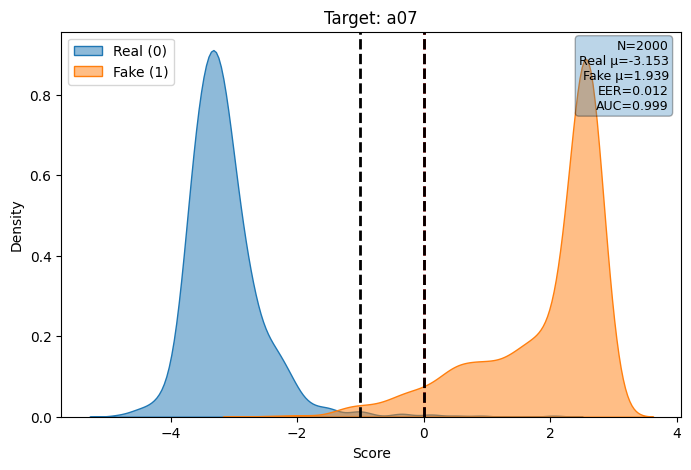

In [7]:
R_THR = -1
F_THR = 0

real_files = []
fake_files = []

for i, (logit, label) in enumerate(zip(attack_logits, attack_labels)):
    if label == 0 and logit < R_THR:
        real_files.append(str(attack_file_IDs[i]))
    elif label == 1 and logit > F_THR:
        fake_files.append(str(attack_file_IDs[i]))

plot_distributions(attack_logits, attack_labels, attack=selected_attack, F_THR=F_THR, R_THR=R_THR)

In [8]:
df_t = pd.read_csv('/Database/SpoofCeleb/metadata/train.csv')
df_d = pd.read_csv('/Database/SpoofCeleb/metadata/development.csv')
df_e = pd.read_csv('/Database/SpoofCeleb/metadata/evaluation.csv')

df = pd.concat([df_t, df_d, df_e], ignore_index=True)
df['attack'].unique()

array(['a00', 'a01', 'a02', 'a03', 'a04', 'a05', 'a06', 'a07', 'a08',
       'a09', 'a10', 'a11', 'a12', 'a13', 'a14', 'a15', 'a16', 'a17',
       'a18', 'a19', 'a20', 'a21', 'a22', 'a23'], dtype=object)

In [9]:
selected_attack

'a07'

In [10]:
df = df[df['attack'].isin(['a00', selected_attack])]
df['file_ID'] = df['file'].str.split('/').str[-1].str.replace('.flac', '', regex=False)
df

,file,speaker,attack,file_ID
0,a00/id11178/LAHad7VLKXw-00007-001.flac,id11178,a00,LAHad7VLKXw-00007-001
1,a00/id10580/VR8MUnB_MTI-00007-003.flac,id10580,a00,VR8MUnB_MTI-00007-003
2,a00/id10105/vJSc3FB4US0-00067-002.flac,id10105,a00,vJSc3FB4US0-00067-002
3,a00/id11013/69_Lld4oKtU-00017-003.flac,id11013,a00,69_Lld4oKtU-00017-003
4,a00/id10413/d6vzz99CWjY-00009-001.flac,id10413,a00,d6vzz99CWjY-00009-001
...,...,...,...,...
2605270,a00/id10276/cytGIvwJ3NA-00002-001.flac,id10276,a00,cytGIvwJ3NA-00002-001
2605271,a00/id10285/m-uILToQ9ss-00003-004.flac,id10285,a00,m-uILToQ9ss-00003-004
2605272,a00/id10294/NRMQOFYS41I-00002-002.flac,id10294,a00,NRMQOFYS41I-00002-002
2605273,a00/id10307/0nH78dDh0N0-00007-004.flac,id10307,a00,0nH78dDh0N0-00007-004


In [11]:
def pick_file(fid):
    rows = df[df['file_ID'] == fid]
    if rows.empty:
        return None
    
    if len(rows) == 1:
        return rows['file'].iloc[0]
    
    filt = rows[rows['file'].str.startswith(selected_attack)]
    
    if not filt.empty:
        return filt['file'].iloc[0]
    
    return rows['file'].iloc[0]

In [12]:
real_files_full = [pick_file(fid) for fid in real_files]
fake_files_full = [pick_file(fid) for fid in fake_files]

In [13]:
print(len(real_files_full))
print(len(fake_files_full))

989
940


In [14]:
random.seed(42)
N = 5

real_separated = random.sample(real_files_full, min(N, len(real_files_full)))
fake_separated = random.sample(fake_files_full, min(N, len(fake_files_full)))
fake_separated

['a07/id10208/grMy4DxVtzA-00005-004.flac',
 'a07/id10915/U8xqFgZutJ0-00009-004.flac',
 'a07/id10674/S1cq0bhSrq4-00016-003.flac',
 'a07/id10892/lpYlc7haTII-00017-003.flac',
 'a07/id11173/YIuxecr7How-00034-001.flac']

In [15]:
from pathlib import Path

roots = [
    Path("/Database/SpoofCeleb/flac/train"),
    Path("/Database/SpoofCeleb/flac/development"),
    Path("/Database/SpoofCeleb/flac/evaluation"),
]

def resolve_file(rel_path):
    for root in roots:
        full_path = root / rel_path
        if full_path.exists():
            return full_path
    return None

real_separated = [resolve_file(p) for p in real_separated]
fake_separated = [resolve_file(p) for p in fake_separated]

print(real_separated)
print(fake_separated)

[PosixPath('/Database/SpoofCeleb/flac/evaluation/a00/id10303/LKDWhdJQFco-00008-001.flac'), PosixPath('/Database/SpoofCeleb/flac/evaluation/a00/id10292/gm6PJowclv0-00004-003.flac'), PosixPath('/Database/SpoofCeleb/flac/evaluation/a00/id10280/9AtE4C309P8-00011-002.flac'), PosixPath('/Database/SpoofCeleb/flac/evaluation/a00/id10302/2Er-cV85fc4-00020-003.flac'), PosixPath('/Database/SpoofCeleb/flac/evaluation/a00/id10286/7I1GtGzVfmw-00011-002.flac')]
[PosixPath('/Database/SpoofCeleb/flac/train/a07/id10208/grMy4DxVtzA-00005-004.flac'), PosixPath('/Database/SpoofCeleb/flac/train/a07/id10915/U8xqFgZutJ0-00009-004.flac'), PosixPath('/Database/SpoofCeleb/flac/train/a07/id10674/S1cq0bhSrq4-00016-003.flac'), PosixPath('/Database/SpoofCeleb/flac/train/a07/id10892/lpYlc7haTII-00017-003.flac'), PosixPath('/Database/SpoofCeleb/flac/train/a07/id11173/YIuxecr7How-00034-001.flac')]


/tmp/ipykernel_2208371/2001536906.py:101: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  waveform = torch.tensor(waveform).float()


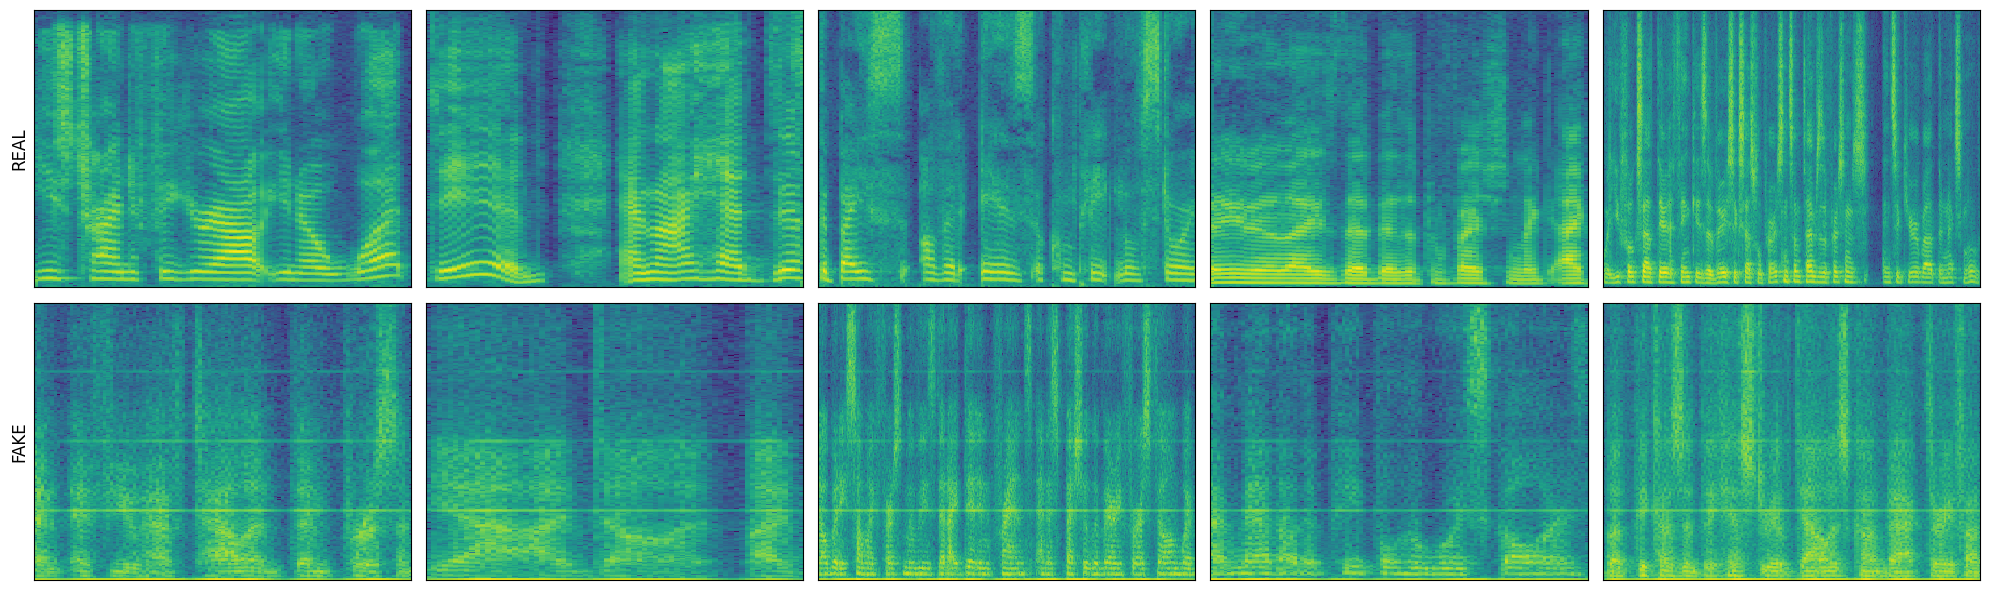

In [16]:
spec_separated = prepare_spectrograms_from_files(real_separated, fake_separated)
plot_spectrograms_from_arrays(spec_separated, titles=["REAL", "FAKE"], N=N)

In [18]:
import scipy.signal as sps
import scipy.ndimage as ndi

stft_params = STFTWindowParams()
stft_params.fft_size

def extract_upsampling_feature(
    x,
    sr=16000,
    n_fft=512,
    hop_length=256,
    baseline_win=32,
    fmin=1000,
    fmax=8000,
):
    """
    Artifact fingerprint: basically an enhanced spectrum
    """
    x = np.asarray(x, dtype=np.float32)
    f, t, Z = sps.stft(
        x,
        fs=sr,
        nperseg=n_fft,
        noverlap=n_fft - hop_length,
        boundary=None,
        padded=False,
    )

    # S = np.abs(Z)
    # S_mean = np.mean(S, axis=1)  # average spectrum
    # mask = (f >= fmin) & (f <= fmax)
    # S_mean = S_mean[mask] # band-limit
    # baseline = ndi.minimum_filter1d(S_mean, size=baseline_win) # baseline removal
    # fingerprint = S_mean - baseline
    # fingerprint = np.maximum(fingerprint, 0.0) # keep only peaks
    # fingerprint /= (np.linalg.norm(fingerprint) + 1e-8) # normalization (L2)
 
    S = np.log(np.abs(Z) + 1e-8) # log magnitude
    S_mean = np.mean(S, axis=1) # average spectrum
    mask = (f >= fmin) & (f <= fmax)
    S_mean = S_mean[mask] # band-limit
    baseline = ndi.gaussian_filter1d(S_mean, sigma=baseline_win / 4) # smooth baseline (~clean envelope)
    fingerprint = S_mean - baseline # deviation from baseline (signed)
    fingerprint /= (np.linalg.norm(fingerprint) + 1e-8)

    return fingerprint.astype(np.float32)

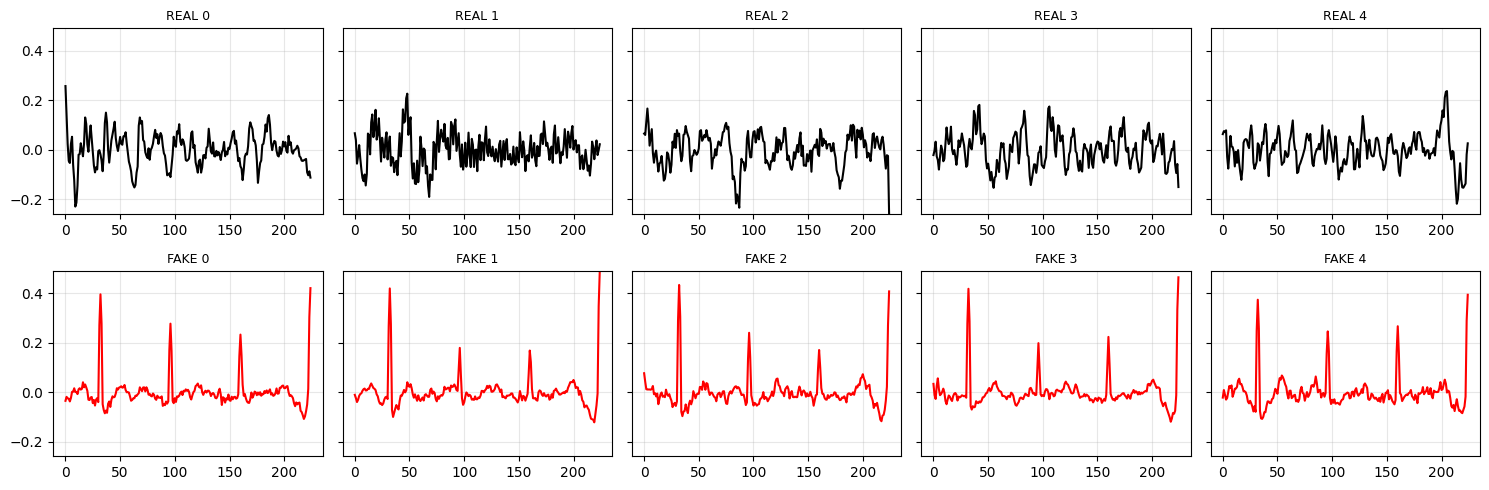

In [19]:
plot_features_grid_2(real_separated, fake_separated, stft_params)

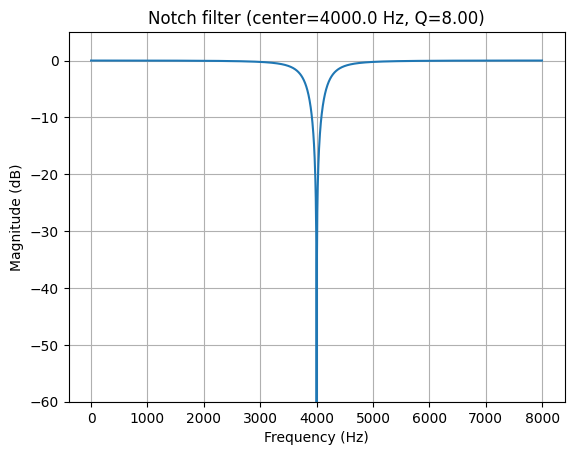

In [99]:
def plot_filter_response(b, a, sr, title="Filter response"):
    w, h = sps.freqz(b, a, worN=2048)
    freqs = w * sr / (2 * np.pi)

    magnitude = 20 * np.log10(np.abs(h) + 1e-8)

    plt.figure()
    plt.plot(freqs, magnitude)
    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.grid(True)
    plt.show()

def plot_notch(sr):
    center = 4000
    Q = 8
    b, a = sps.iirnotch(center / (sr / 2), Q)
    w, h = sps.freqz(b, a, worN=2048, fs=sr)

    plt.figure()
    plt.plot(w, 20 * np.log10(np.abs(h) + 1e-8))
    plt.title(f"Notch filter (center={center:.1f} Hz, Q={Q:.2f})")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude (dB)")
    plt.ylim(-60, 5)
    plt.grid()
    plt.show()

plot_notch(16000)

In [103]:
# Tonal artifact
def add_sparse_resonances(x, sr, n_peaks=2):
    y = np.zeros_like(x)

    for _ in range(n_peaks):
        freq = np.random.uniform(1000, 8000)  # same band as your feature
        Q = np.random.uniform(30, 80)         # very sharp peaks

        b, a = sps.iirpeak(freq / (sr / 2), Q=Q)
        peak = sps.lfilter(b, a, x)

        gain = np.random.uniform(2.0, 5.0)    # dominant amplitude
        y += gain * peak

    return y
    
# Filtering Artifact
def apply_random_filter_coloration(x, sr):

    # Low-pass filter (main effect: high-frequency attenuation)
    cutoff = np.random.uniform(4000, 6000)
    order = np.random.randint(2, 8)
    b, a = sps.butter(order, cutoff / (sr / 2), btype='low')
    plot_filter_response(b, a, sr, "Low-pass")
    y = sps.lfilter(b, a, x)

    if np.random.rand() < 0.85:
        center = np.random.uniform(1500, 6000)
        Q = np.random.uniform(8.0, 18.0)
        b_notch, a_notch = sps.iirnotch(center / (sr / 2), Q)
        y = sps.lfilter(b_notch, a_notch, y)

    return y

def simulate_upsampling_artifact(x, sr=16000):
    # Step 1: kill most of the original spectrum
    y = x * 0.05

    # Step 2: inject sparse dominant peaks / generate filtered version
    
    #n_peaks = np.random.randint(1, 3)
    #mod = add_sparse_resonances(x, sr, n_peaks=n_peaks)
    
    mod = apply_random_filter_coloration(x, sr)

    # Step 3: combine
    y = y + mod

    # Step 4: slight nonlinearity (increase contrast)
    y = np.sign(y) * (np.abs(y) ** 1.5)

    # normalize
    y /= np.max(np.abs(y)) + 1e-8
    return y.astype(np.float32)


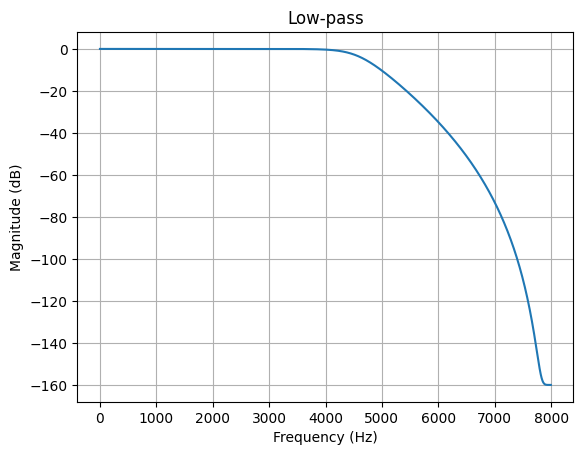

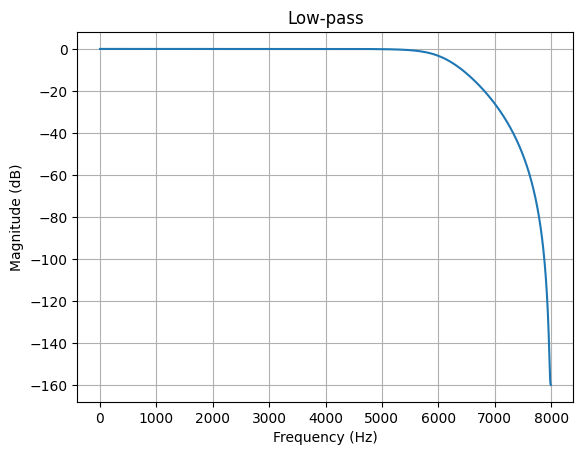

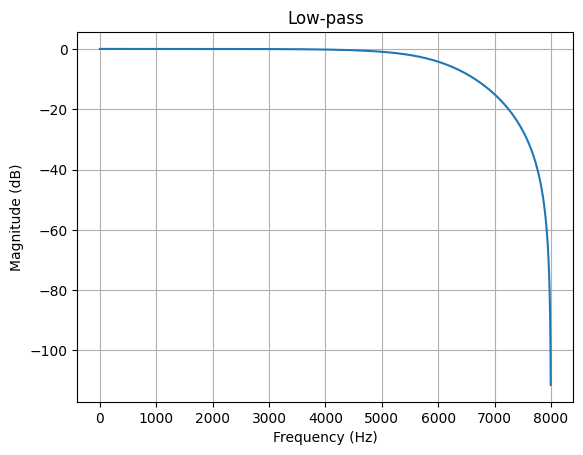

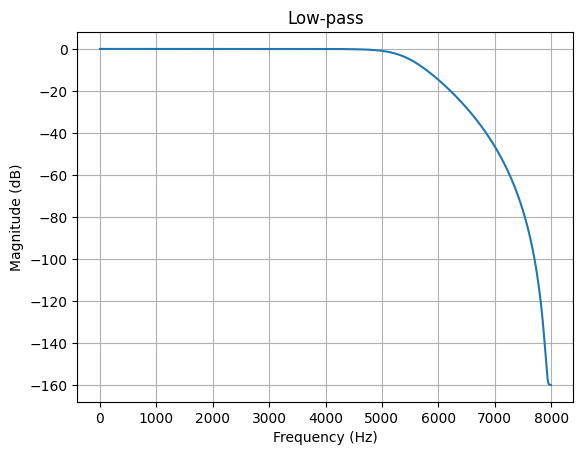

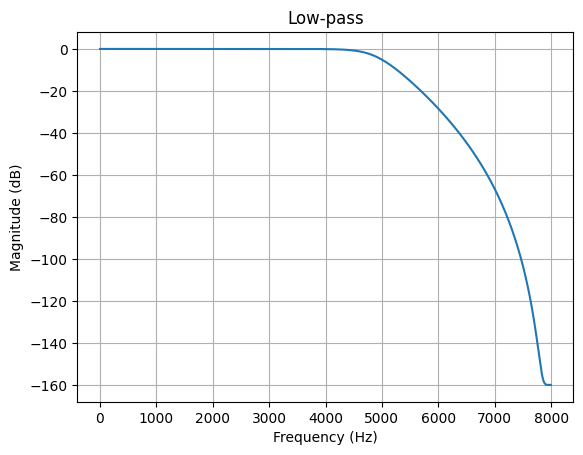

In [104]:
manip_separated = []

for p in real_separated:
    x = load_audio_track(p, trim=True, normalize=True)
    y = simulate_upsampling_artifact(x.numpy())
    manip_separated.append(y)

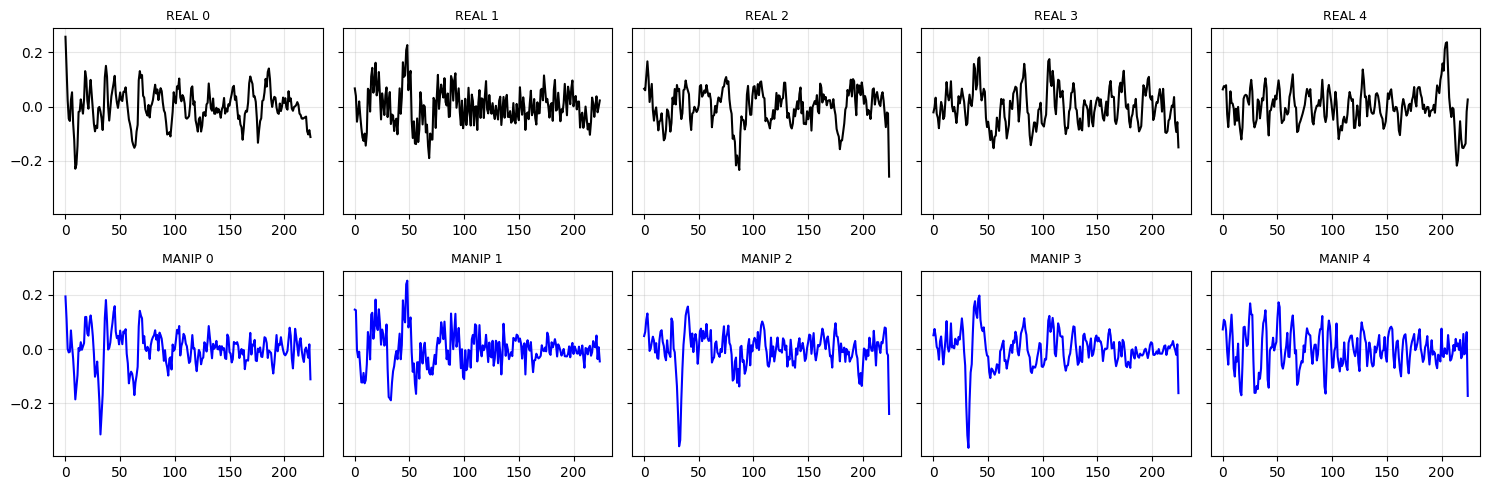

In [102]:
plot_features_grid_3(real_separated, fake_separated, manip_separated, stft_params)